# 04 – Approach A3: DistilBERT with Overlapping Sliding Windows
**DS5007 NLP · Assignment 2 · Extractive QA on SQuAD 1.1**

**Problem with A2.** A Transformer reads a fixed maximum number of tokens (512 for DistilBERT; we use 384 to save memory and time). With plain truncation, any answer after the cut is impossible to find.

**Idea of A3.** Split a long context into **overlapping windows** and pair *each* window with the full question:
```
context tokens:  c1 ………………………………………………………………………………………………………… c800
window 0:        [CLS] q [SEP] c1   … c365 [SEP]
window 1:        [CLS] q [SEP] c238 … c602 [SEP]        ← starts doc_stride=128 tokens before window 0 ends
window 2:        [CLS] q [SEP] c475 … c800 [SEP]
```
* **Training:** a window whose context contains the whole gold answer gets the token labels of the answer *inside that window*. Windows without the (complete) answer are labelled `[CLS]` (0, 0), so the model also learns to give low scores to irrelevant windows.
* **Inference:** every window is scored, and the best valid span **over all windows** of the question wins. Its token offsets map it back to the **original** context string.
* **Overlap** (`doc_stride` = 128 tokens) guarantees that an answer cut by one window boundary appears complete, with surrounding context, in the next window.

**When are windows useful?** Whenever contexts are longer than the input limit, e.g. long documents, short `max_length` for speed or memory, or models with small position limits. On SQuAD at 384 tokens only ≈1.7% of validation pairs are too long (notebook 01), so a small but real gain is expected here. At 128 tokens, 79% of pairs are too long (Experiment C/D in notebook 05).

**Computational trade-offs.** (i) More inputs: every extra window costs a full forward pass, and the overlapping tokens are processed twice. (ii) Training sees extra mostly-`[CLS]` windows. (iii) Scores from different windows are compared directly, although each window's softmax is normalised separately. Everything else (model, hyper-parameters, heads, loss, metrics) is **identical to A2**, so A2 vs A3 isolates the effect of the windows.

## 1. Setup and data: overlapping windows

In [1]:
# Environment: on Google Colab, mount Drive and work inside the uploaded project folder; locally nothing to do.
import os, sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = "/content/drive/MyDrive/EQA_Assignment"      # <- path of the uploaded project folder
    os.chdir(os.path.join(PROJECT_DIR, "notebooks"))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "transformers>=4.40", "datasets", "gradio"])
sys.path.insert(0, os.path.abspath(".."))                     # make eqa_lib.py (project root) importable

import eqa_lib as eqa          # imported first: it initialises OpenSSL before torch/pyarrow (Windows workaround)
import json, time, re, collections, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 120)
ENV = eqa.setup()

HEADLESS = os.environ.get("EQA_HEADLESS", "0") == "1"

python         : 3.14.6
torch          : 2.14.1+cu126
transformers   : 5.19.0
numpy          : 2.4.6
pandas         : 3.0.3
device         : cuda
gpu            : NVIDIA GeForce RTX 4050 Laptop GPU
gpu_memory_gb  : 6.0
cuda           : 12.6
amp_dtype      : torch.bfloat16
seed           : 42
quick_run      : False
force_retrain  : False
project_root   : C:\Users\kiran\NLP Assignment 2\EQA_Assignment


In [2]:
RUN = "distilbert_sliding_window"
RC = dict(arch="pretrained", encoder="distilbert-base-uncased",
          input_strategy="sliding_window", max_length=384, doc_stride=128,
          lr=5e-5, batch_size=16, epochs=2, warmup_ratio=0.1, weight_decay=0.01, max_grad_norm=1.0,
          evals_per_epoch=2, patience=2, train_fraction=1.0)
if eqa.QUICK_RUN:
    RC["epochs"], RC["evals_per_epoch"] = 1, 1
print(json.dumps(RC, indent=2))

train_raw, val_df, _ = eqa.load_squad()
train_df, _ = eqa.clean_training_data(train_raw)
tokenizer = eqa.get_tokenizer()
train_feats, train_stats = eqa.prepare_features(train_df, tokenizer, RC["max_length"], RC["doc_stride"], sliding_window=True)
val_feats, val_stats = eqa.prepare_features(val_df, tokenizer, RC["max_length"], RC["doc_stride"], sliding_window=True, keep_offsets=True)
display(pd.DataFrame({"train": train_stats, "validation": val_stats}).drop(index="mismatch_examples"))
wpe = pd.Series(val_feats["example_idx"]).value_counts()
print(f"Validation: {len(val_df):,} questions -> {len(val_feats['input_ids']):,} windows "
      f"({(wpe > 1).sum()} questions need more than one window, max {wpe.max()} windows); "
      f"answers unreachable: {val_stats['examples_whose_answer_is_unreachable']} (A2 with truncation: 34)")

{
  "arch": "pretrained",
  "encoder": "distilbert-base-uncased",
  "input_strategy": "sliding_window",
  "max_length": 384,
  "doc_stride": 128,
  "lr": 5e-05,
  "batch_size": 16,
  "epochs": 2,
  "warmup_ratio": 0.1,
  "weight_decay": 0.01,
  "max_grad_norm": 1.0,
  "evals_per_epoch": 2,
  "patience": 2,
  "train_fraction": 1.0
}


Generating train split:   0%|          | 0/87599 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/10570 [00:00<?, ? examples/s]

Loaded from datasets.load_dataset('rajpurkar/squad'): 87,599 training / 10,570 validation examples


,train,validation
questions_truncated,0,0
windows_with_answer,87785,10612
span_exact_match,87559,10580
windows_without_answer,739,172
span_mismatch,226,32
examples,87599,10570
features,88524,10784
examples_with_answer_in_some_window,87599,10570
examples_whose_answer_is_unreachable,0,0


Validation: 10,570 questions -> 10,784 windows (183 questions need more than one window, max 3 windows); answers unreachable: 0 (A2 with truncation: 34)


### 1.1 Overflow mapping and answer-to-window assignment on a real example
`overflow_to_sample_mapping` (stored as `example_idx`) links every window to its question. `window_idx` numbers the windows, and the offset mapping gives each window's character range in the original context. Below, the longest validation context is shown with the window that contains the gold answer.

In [3]:
ex = int(wpe.idxmax())
row = val_df.iloc[ex]
fids = [f for f, e in enumerate(val_feats["example_idx"]) if e == ex]
gold_start = row["answer_starts"][0]; gold_end = gold_start + len(row["answer_texts"][0])
print(f"Question: {row['question']!r}\nGold answer: {row['answer_texts'][0]!r} at characters [{gold_start}, {gold_end}) "
      f"of a {len(row['context'])}-character context\n")
win_rows = []
for f in fids:
    offs = [o for o in val_feats["offset_mapping"][f] if o is not None]
    win_rows.append({"feature": f, "example_idx (overflow mapping)": val_feats["example_idx"][f], "window_idx": val_feats["window_idx"][f],
                     "tokens": len(val_feats["input_ids"][f]), "context chars covered": f"[{offs[0][0]}, {offs[-1][1]})",
                     "start_position": val_feats["start_positions"][f], "end_position": val_feats["end_positions"][f],
                     "contains answer": val_feats["start_positions"][f] > 0})
display(pd.DataFrame(win_rows))

Question: 'Which two governing bodies have legislative veto power?'
Gold answer: 'the European Parliament and the Council of the European Union' at characters [63, 124) of a 3326-character context



,feature,example_idx (overflow mapping),window_idx,tokens,context chars covered,start_position,end_position,contains answer
0,4179,4142,0,384,"[0, 2117)",21,30,True
1,4180,4142,1,384,"[1415, 3325)",0,0,False
2,4181,4142,2,141,"[2685, 3326)",0,0,False


## 2. Model and training
Identical to A2: pretrained `distilbert-base-uncased` + the shared span heads, AdamW lr 5e-5, batch 16, 2 epochs, 10% warm-up, clipping 1.0, bf16, evaluation every half epoch, best-F1 checkpoint saved to `models/distilbert_sliding_window/`, early stopping with patience 2. **The only change is the input: 88,524 overlapping windows instead of 87,599 truncated inputs.**

In [4]:
model, hist = eqa.train_model(RUN, RC, train_feats, val_feats, val_df, model_dir=eqa.PATHS.models / RUN)

[cache] 'distilbert_sliding_window' already trained – replaying its saved log (set EQA_FORCE_RETRAIN=1 to retrain).
=== distilbert_sliding_window: 66.36M params | 87,599 questions -> 88,524 inputs | 2 epochs x 5533 steps (batch 16, lr 5e-05) ===
[distilbert_sliding_window] epoch 1/2 step   553/5533 | train loss 3.6241 | lr 2.50e-05 |   0.9 min, ETA  16.8 min
[distilbert_sliding_window] epoch 1/2 step  1106/5533 | train loss 1.8590 | lr 5.00e-05 |   1.8 min, ETA  16.2 min
[distilbert_sliding_window] epoch 1/2 step  1659/5533 | train loss 1.6236 | lr 4.72e-05 |   2.7 min, ETA  15.5 min
[distilbert_sliding_window] epoch 1/2 step  2212/5533 | train loss 1.4427 | lr 4.44e-05 |   3.6 min, ETA  14.6 min
[distilbert_sliding_window] epoch 1/2 step  2765/5533 | train loss 1.3788 | lr 4.17e-05 |   4.6 min, ETA  13.7 min
[distilbert_sliding_window] >>> eval @ epoch 0.50: train loss 1.9856 | val loss 1.3364 | EM 70.63 | F1 80.00  (new best)
[distilbert_sliding_window] epoch 1/2 step  3318/5533 | tr

## 3. Results
### 3.1 Training and validation curves

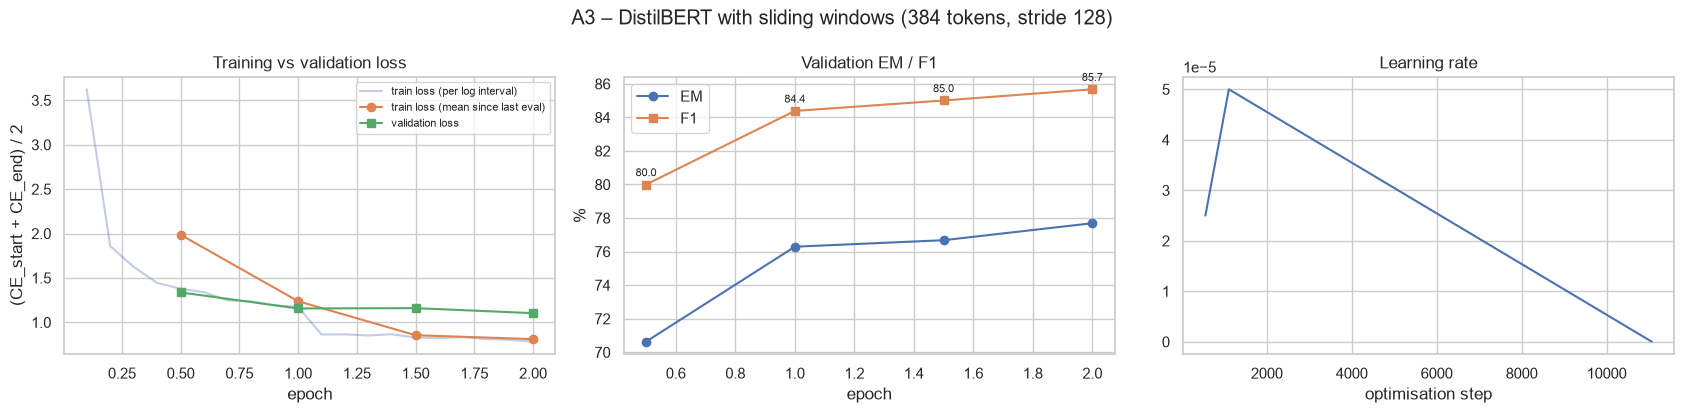

,epoch,train_loss,val_loss,exact_match,f1,elapsed_min
0,0.5,1.986,1.336,70.634,79.997,4.850
1,1.0,1.237,1.156,76.291,84.382,9.765
2,1.5,0.855,1.159,76.679,85.006,14.714
3,2.0,0.811,1.103,77.692,85.673,19.709


In [5]:
eqa.plot_history(hist, "A3 – DistilBERT with sliding windows (384 tokens, stride 128)")
eqa.savefig("04_A3_training_curves")
display(pd.DataFrame(hist["evals"])[["epoch", "train_loss", "val_loss", "exact_match", "f1", "elapsed_min"]].round(3))

In [6]:
ev = eqa.evaluate_model(model, val_feats, val_df)
print(f"A3 best checkpoint (epoch {hist['best']['epoch']:.1f}) on the full validation set ({len(val_df):,} questions):")
print(f"   Exact Match = {ev['exact_match']:.2f}   F1 = {ev['f1']:.2f}   validation loss = {ev['val_loss']:.4f}")
print(f"   training time {hist['train_time_min']:.1f} min ({hist['pure_train_time_min']:.1f} min excluding validation), "
      f"peak GPU memory {hist['peak_gpu_mem_gb']:.2f} GB")
print(f"   inference: {ev['forward_seconds']:.1f} s for {ev['n_features']:,} windows ({ev['features_per_sec']:.0f} windows/s) | "
      f"checkpoint {hist['model_size_mb']:.0f} MB")
row = eqa.experiment_row(RUN, "A3 DistilBERT + sliding windows", hist, ev, "sliding_window", RC["max_length"], RC["doc_stride"])
logs = eqa.log_experiment(row)
eqa.save_json(ev["predictions"], eqa.PATHS.results / f"predictions_{RUN}.json")
ev["details"].to_csv(eqa.PATHS.results / f"details_{RUN}.csv", index=False)
cols = ["approach", "input_strategy", "params_M", "train_inputs", "pure_train_time_min", "val_inputs", "inference_s_full_val", "EM", "F1"]
logs[cols].round(2)

A3 best checkpoint (epoch 2.0) on the full validation set (10,570 questions):
   Exact Match = 77.69   F1 = 85.67   validation loss = 1.1030
   training time 19.7 min (18.5 min excluding validation), peak GPU memory 2.08 GB
   inference: 13.8 s for 10,784 windows (782 windows/s) | checkpoint 265 MB


,approach,input_strategy,params_M,train_inputs,pure_train_time_min,val_inputs,inference_s_full_val,EM,F1
0,A1 Transformer from scratch,sliding_window,11.11,88524,12.25,10784,4.83,10.53,20.09
1,A2 DistilBERT (truncation),truncation,66.36,87599,18.52,10570,14.21,78.06,85.89
2,A3 DistilBERT + sliding windows,sliding_window,66.36,88524,18.51,10784,13.78,77.69,85.67


### 3.2 Where do windows make a difference? A2 (truncation) vs A3 (windows) on the same questions
The two models differ only in their input strategy, so we compare them per question, split by whether the context fits into one 384-token input.

In [7]:
val_eda = eqa.add_eda_columns(val_df, tokenizer)
a2 = pd.read_csv(eqa.PATHS.results / "details_distilbert_baseline.csv")[["id", "em", "f1", "prediction"]]
a3 = ev["details"][["id", "em", "f1", "prediction", "window"]]
cmp = val_eda[["id", "question", "answer_texts", "pair_tokens", "answer_start_token_in_context", "question_tokens"]] \
    .merge(a2, on="id").merge(a3, on="id", suffixes=("_A2", "_A3"))
cmp["context_fits_384"] = cmp["pair_tokens"] <= 384
cmp["answer_beyond_cut"] = cmp["answer_start_token_in_context"] > 384 - 3 - cmp["question_tokens"]
groups = {"all questions": cmp, "context fits into 384 tokens": cmp[cmp["context_fits_384"]],
          "context longer than 384 tokens": cmp[~cmp["context_fits_384"]],
          "answer beyond the truncation point": cmp[cmp["answer_beyond_cut"]]}
tbl = pd.DataFrame({k: {"questions": len(g), "EM A2 (truncation)": 100 * g["em_A2"].mean(), "EM A3 (windows)": 100 * g["em_A3"].mean(),
                        "F1 A2 (truncation)": 100 * g["f1_A2"].mean(), "F1 A3 (windows)": 100 * g["f1_A3"].mean()}
                    for k, g in groups.items()}).T.round(2)
display(tbl)
tbl.to_csv(eqa.PATHS.results / "A2_vs_A3_by_context_length.csv")
print(f"A3 answers taken from a window other than the first: {(cmp['window'] > 0).sum()} questions")
for r in cmp[cmp["answer_beyond_cut"] & (cmp["f1_A3"] > cmp["f1_A2"])].head(3).itertuples():
    print(f"\nQ: {r.question}\n   gold: {list(dict.fromkeys(r.answer_texts))}\n   A2 (truncation): {r.prediction_A2!r}\n"
          f"   A3 (windows, answer from window {r.window}): {r.prediction_A3!r}")

,questions,EM A2 (truncation),EM A3 (windows),F1 A2 (truncation),F1 A3 (windows)
all questions,10570.0,78.06,77.69,85.89,85.67
context fits into 384 tokens,10387.0,78.21,77.67,86.05,85.65
context longer than 384 tokens,183.0,69.40,78.69,76.26,86.93
answer beyond the truncation point,32.0,6.25,68.75,14.93,83.64


A3 answers taken from a window other than the first: 57 questions

Q: What website are teachers using to sell their lesson plans?
   gold: ['TeachersPayTeachers.com']
   A2 (truncation): 'Merit pay systems'
   A3 (windows, answer from window 1): 'TeachersPayTeachers.com'

Q: How much of a voting majority must there be to effectively censure the Commission?
   gold: ['two-thirds majority', 'a two-thirds majority']
   A2 (truncation): 'ten times the voting weight in Parliament as citizens of the largest countries'
   A3 (windows, answer from window 2): 'two-thirds'

Q: Which party is currently the largest among political party lines?
   gold: ["the conservative European People's Party", "European People's Party"]
   A2 (truncation): 'democratic'
   A3 (windows, answer from window 1): "conservative European People's Party"


### 3.3 Is the overall difference between A2 and A3 real? (paired bootstrap)
Both models are evaluated on the same 10,570 questions, so we resample *questions* with replacement (2,000 times) and recompute the difference in EM/F1. If the 95% confidence interval contains 0, the overall difference is within run-to-run noise.

In [8]:
rng = np.random.default_rng(eqa.SEED)
n = len(cmp)
rows = []
for metric in ("em", "f1"):
    diff = (cmp[f"{metric}_A3"] - cmp[f"{metric}_A2"]).to_numpy()
    boots = np.array([diff[rng.integers(0, n, n)].mean() for _ in range(2000)]) * 100
    long_diff = diff[~cmp["context_fits_384"].to_numpy()]
    lboots = np.array([long_diff[rng.integers(0, len(long_diff), len(long_diff))].mean() for _ in range(2000)]) * 100
    rows.append({"metric": metric.upper(), "A3 − A2 (all questions)": 100 * diff.mean(),
                 "95% CI (all)": f"[{np.percentile(boots, 2.5):+.2f}, {np.percentile(boots, 97.5):+.2f}]",
                 "A3 − A2 (contexts > 384 tokens)": 100 * long_diff.mean(),
                 "95% CI (long)": f"[{np.percentile(lboots, 2.5):+.2f}, {np.percentile(lboots, 97.5):+.2f}]"})
boot_tbl = pd.DataFrame(rows).round(2)
boot_tbl.to_csv(eqa.PATHS.results / "A2_vs_A3_bootstrap.csv", index=False)
boot_tbl

,metric,A3 − A2 (all questions),95% CI (all),A3 − A2 (contexts > 384 tokens),95% CI (long)
0,EM,-0.37,"[-1.00, +0.26]",9.29,"[+3.28, +15.85]"
1,F1,-0.21,"[-0.66, +0.25]",10.67,"[+5.15, +16.82]"


## 4. Reusable inference function
`eqa.predict(model, context, question)` runs the complete pipeline on raw text: packing (+ windows), a forward pass, the best-span search over all windows, and extraction of the answer from the **original** context by character offsets. An `assert` inside the function guarantees that the answer is an exact substring of the context.

**Output:** the answer, start/end **character** positions, start/end **token** positions (indices into the winning window's `[CLS] q [SEP] c [SEP]` sequence) with their WordPiece tokens, the window used, and the confidence $P_{start}(\hat i)\cdot P_{end}(\hat j)$.

The demonstrations use the **best-performing trained model** among A1–A3 (highest validation F1 in `results/experiment_logs.csv`).

In [9]:
eqa.show_source(eqa.predict)
logs = pd.read_csv(eqa.PATHS.results / "experiment_logs.csv")
main = logs[logs["run"].isin(["transformer_scratch", "distilbert_baseline", "distilbert_sliding_window"])]
best = main.sort_values("F1", ascending=False).iloc[0]
print(f"Best-performing model: {best['approach']} (run '{best['run']}', EM {best['EM']:.2f}, F1 {best['F1']:.2f})")
best_model = model if best["run"] == RUN else eqa.load_qa_model(eqa.PATHS.models / best["run"])
BEST_WINDOWS = best["input_strategy"] == "sliding_window"
qa = lambda c, q: eqa.predict(best_model, c, q, sliding_window=BEST_WINDOWS, max_length=384, doc_stride=128)

```python
def predict(model, context: str, question: str, sliding_window: bool = True, max_length: int = 384, doc_stride: int = 128):
    """Answer `question` from `context` with a trained QA model.

    Runs exactly the evaluation pipeline on one example: question/context packing (+ overlapping windows if
    `sliding_window`), a forward pass, the constrained best-span search over all windows, and extraction of the
    answer from the ORIGINAL context with the character offsets of the winning tokens.

    Returns a dict with the answer text, its character span, the start/end token positions (indices into the
    winning window's `[CLS] q [SEP] c [SEP]` sequence) and their WordPiece tokens, the window used, and the
    confidence P_start(start) * P_end(end).
    """
    tok = get_tokenizer()
    df = pd.DataFrame({"id": ["q0"], "context": [context], "question": [question],
                       "answer_texts": [[""]], "answer_starts": [[-1]]})
    feats, _ = prepare_features(df, tok, max_length, doc_stride, sliding_window=sliding_window, keep_offsets=True)
    sl, el, _ = get_logits(model, feats, batch_size=16)
    _, details = postprocess_predictions(df, feats, sl, el)
    r = details.iloc[0]
    out = {"answer": r["prediction"], "start_char": int(r["start_char"]), "end_char": int(r["end_char"]),
           "start_token": int(r["start_token"]), "end_token": int(r["end_token"]), "window": int(r["window"]),
           "n_windows": len(feats["input_ids"]), "confidence": float(r["confidence"]), "answer_tokens": []}
    if out["window"] >= 0:
        f = feats["window_idx"].index(out["window"])
        out["answer_tokens"] = tok.convert_ids_to_tokens(feats["input_ids"][f][out["start_token"]:out["end_token"] + 1])
        assert context[out["start_char"]:out["end_char"]] == out["answer"]      # always an exact substring
    return out

```

Best-performing model: A2 DistilBERT (truncation) (run 'distilbert_baseline', EM 78.06, F1 85.89)


In [10]:
long_row = val_eda.loc[val_eda["id"].isin(cmp.loc[cmp["answer_beyond_cut"], "id"])].iloc[0]
demos = [
    ("1. Simple factual question (from the brief)",
     "Alan Turing was a British mathematician and computer scientist. He introduced the concept of the Turing machine in 1936.",
     "In which year did Alan Turing introduce the Turing machine?", "1936"),
    ("2. Answer near the beginning (name)",
     "Marie Curie was the first woman to win a Nobel Prize. She was born in Warsaw in 1867 and later moved to Paris, where she "
     "studied physics and mathematics. Together with her husband Pierre she discovered the elements polonium and radium.",
     "Who was the first woman to win a Nobel Prize?", "Marie Curie"),
    ("3. Answer near the end",
     "The Amazon rainforest covers much of the Amazon basin of South America. The majority of the forest is contained within "
     "Brazil, with 60% of the rainforest, followed by Peru with 13% and Colombia with 10%. It is the largest tropical rainforest "
     "in the world. The river that flows through it discharges more water than any other river and empties into the Atlantic Ocean.",
     "Into which ocean does the Amazon river empty?", "Atlantic Ocean"),
    ("4. Number among several numbers",
     "The Amazon rainforest covers much of the Amazon basin of South America. The majority of the forest is contained within "
     "Brazil, with 60% of the rainforest, followed by Peru with 13% and Colombia with 10%.",
     "What percentage of the rainforest is in Peru?", "13%"),
    ("5. Long paragraph – answer beyond the first 384-token window (validation example)",
     long_row["context"], long_row["question"], long_row["answer_texts"][0]),
    ("6. Hard case – answer requires arithmetic (not a span)",
     "The company was founded in 1998 by two students. It moved its headquarters to Mountain View in 2003 and went public in 2004.",
     "How many years after its founding did the company move to Mountain View?", "5"),
    ("7. Hard case – the question is not answerable from the text",
     "Alan Turing was a British mathematician and computer scientist. He introduced the concept of the Turing machine in 1936.",
     "Where was Alan Turing born?", "(not in the text)"),
]
other_run = "distilbert_sliding_window" if best["run"] != "distilbert_sliding_window" else "distilbert_baseline"
other_model = model if other_run == RUN else eqa.load_qa_model(eqa.PATHS.models / other_run)
other_label = "A3 (windows)" if other_run == "distilbert_sliding_window" else "A2 (truncation)"
rows = []
for case, ctx, q, expected in demos:
    r = qa(ctx, q)
    o = eqa.predict(other_model, ctx, q, sliding_window=(other_run == "distilbert_sliding_window"))
    assert ctx[r["start_char"]:r["end_char"]] == r["answer"] and ctx[o["start_char"]:o["end_char"]] == o["answer"]
    rows.append({"case": case, "question": q, "expected": expected, "predicted answer (best model)": r["answer"],
                 "start/end char": f"[{r['start_char']}, {r['end_char']})", "start/end token": f"{r['start_token']} / {r['end_token']}",
                 "answer tokens": " ".join(r["answer_tokens"]), "window": f"{r['window'] + 1} of {r['n_windows']}",
                 "confidence": round(r["confidence"], 3),
                 "EM": eqa.exact_match_score(r["answer"], expected), "F1": round(eqa.f1_score(r["answer"], expected), 2),
                 f"{other_label} answer": o["answer"], f"{other_label} window": f"{o['window'] + 1} of {o['n_windows']}",
                 f"{other_label} confidence": round(o["confidence"], 3)})
demo_tbl = pd.DataFrame(rows)
demo_tbl.to_csv(eqa.PATHS.results / "inference_demonstrations.csv", index=False)
print(f"Best model: {best['approach']}; for comparison the last three columns show {other_label}.")
print("All predicted answers are exact substrings of their contexts.")
demo_tbl

Best model: A2 DistilBERT (truncation); for comparison the last three columns show A3 (windows).
All predicted answers are exact substrings of their contexts.


,case,question,expected,predicted answer (best model),start/end char,start/end token,answer tokens,window,confidence,EM,F1,A3 (windows) answer,A3 (windows) window,A3 (windows) confidence
0,1. Simple factual question (from the brief),In which year did Alan Turing introduce the Turing machine?,1936,1936,"[115, 119)",32 / 32,1936,1 of 1,0.996,1.0,1.0,1936,1 of 1,0.997
1,2. Answer near the beginning (name),Who was the first woman to win a Nobel Prize?,Marie Curie,Marie Curie,"[0, 11)",13 / 15,marie cu ##rie,1 of 1,1.000,1.0,1.0,Marie Curie,1 of 1,0.999
2,3. Answer near the end,Into which ocean does the Amazon river empty?,Atlantic Ocean,Atlantic Ocean,"[352, 366)",83 / 84,atlantic ocean,1 of 1,0.712,1.0,1.0,Atlantic Ocean,1 of 1,0.724
3,4. Number among several numbers,What percentage of the rainforest is in Peru?,13%,13%,"[177, 180)",45 / 46,13 %,1 of 1,0.510,1.0,1.0,13%,1 of 1,0.943
4,5. Long paragraph – answer beyond the first 384-token window (validation example),What website are teachers using to sell their lesson plans?,TeachersPayTeachers.com,Merit pay systems,"[1785, 1802)",353 / 355,merit pay systems,1 of 1,0.037,0.0,0.0,TeachersPayTeachers.com,2 of 2,0.770
5,6. Hard case – answer requires arithmetic (not a span),How many years after its founding did the company move to Mountain View?,5,2003,"[95, 99)",34 / 34,2003,1 of 1,0.609,0.0,0.0,2003,1 of 1,0.694
6,7. Hard case – the question is not answerable from the text,Where was Alan Turing born?,(not in the text),British,"[18, 25)",12 / 12,british,1 of 1,0.996,0.0,0.0,British,1 of 1,0.979


## 5. Interactive demonstration (optional)
A small Gradio app: paste a paragraph, type a question, click **Predict**, and see the extracted answer (highlighted in the paragraph), its confidence and its token/character positions. Pasted paragraphs can be arbitrarily long, so the interface uses the **sliding-window model (A3)**, which handles any context length. The same app is available as `python app.py` from the project root. The server is only launched when the notebook is run interactively (not head-less).

In [11]:
import gradio as gr
app_model = model                      # A3: sliding windows, robust to long paragraphs

def gradio_predict(context, question):
    if not context or not context.strip() or not question or not question.strip():
        return "Please enter both a paragraph and a question.", "", "", []
    r = eqa.predict(app_model, context, question, sliding_window=True)
    s, e = r["start_char"], r["end_char"]
    positions = (f"start token {r['start_token']}, end token {r['end_token']} (window {r['window'] + 1} of {r['n_windows']}); "
                 f"characters [{s}, {e})")
    return r["answer"], f"{100 * r['confidence']:.1f} %", positions, [(context[:s], None), (context[s:e], "answer"), (context[e:], None)]

with gr.Blocks() as demo:
    gr.Markdown("## Extractive QA – DistilBERT + sliding windows (A3), fine-tuned on SQuAD 1.1\n"
                "The answer is always a span copied from your paragraph.")
    with gr.Row():
        with gr.Column():
            ctx_in = gr.Textbox(label="Context paragraph", lines=10)
            q_in = gr.Textbox(label="Question")
            btn = gr.Button("Predict", variant="primary")
        with gr.Column():
            ans_out, conf_out = gr.Textbox(label="Extracted answer"), gr.Textbox(label="Confidence (P_start × P_end)")
            pos_out, hl_out = gr.Textbox(label="Token / character positions"), gr.HighlightedText(label="Answer in context")
    btn.click(gradio_predict, [ctx_in, q_in], [ans_out, conf_out, pos_out, hl_out])
    gr.Examples([[d[1], d[2]] for d in demos[:4]], [ctx_in, q_in])

print("Test call:", gradio_predict(demos[0][1], demos[0][2])[:3])
if HEADLESS:
    print("Head-less execution: interface built but not launched. Run this cell interactively or use `python app.py`.")
else:
    demo.launch(share=IN_COLAB, inline=True)

Test call: ('1936', '99.7 %', 'start token 32, end token 32 (window 1 of 1); characters [115, 119)')
Head-less execution: interface built but not launched. Run this cell interactively or use `python app.py`.


## 6. Discussion: when do sliding windows pay off?
**Results (measured above).** A3 reaches **EM 77.69 / F1 85.67**, compared with **EM 78.06 / F1 85.89** for A2. Training cost is identical (18.5 min of optimisation, 88,524 vs 87,599 inputs), A3 uses 2.08 GB vs 2.33 GB peak memory, and validation inference takes 14.4 s for 10,784 windows vs 14.2 s for 10,570 inputs.

**Overall: no measurable difference.** The paired bootstrap shows that the overall gap (−0.37 EM, −0.21 F1) is well inside run-to-run noise: the 95% CI of the F1 difference is [−0.66, +0.25]. At 384 tokens, 98.3% of validation questions fit into a single input, so for them A2 and A3 see *identical* inputs and differ only through training randomness.

**On long contexts: windows clearly win.**
| Questions | n | A2 (truncation) F1 | A3 (windows) F1 |
|---|---|---|---|
| context longer than 384 tokens | 183 | 76.26 | **86.93** (+10.7, 95% CI [+5.2, +16.8]) |
| answer beyond the truncation point | 32 | 14.93 | **83.64** (+68.7) |

For answers that lie after the cut, truncation is almost always wrong. A2 can only pick a distractor from the visible part (*"Merit pay systems"* instead of *"TeachersPayTeachers.com"*), whereas A3 finds the answer in a later window: 57 of its answers come from window 2 or 3. In demonstration 5 the A2 model returns a wrong span but with a low confidence (0.04), while A3 answers correctly from window 2 with confidence 0.77.

**When overlapping windows are useful.**
* Contexts longer than the input limit: long documents, or short `max_length` chosen to save memory or time. Experiment C/D (notebook 05) shows the effect grows sharply at 128–256 tokens.
* Whenever a *wrong* answer is costly. Windows remove a hard failure mode (answer unreachable) at almost no cost on short contexts.

**Computational trade-offs.**
* Cost grows with the number of windows: here only +1.1% inputs (training) and +2.0% (validation). At `max_length` 128 the same validation set needs 2.2× as many inputs (notebook 01).
* Overlapping tokens are encoded twice (stride 128 means up to a third of a window is repeated).
* Windows without the answer add `[CLS]`-labelled training inputs (739 here). Window scores are compared across separately normalised softmaxes, which can occasionally favour a confident wrong window.

**Limitations shown by the demonstrations (both models).** Neither model can compute (demo 6: *"2003"* instead of *5*) or abstain. For a question whose answer is not in the paragraph (demo 7: *"Where was Alan Turing born?"*), both return *"British"* with high confidence (≈0.98–1.0), because SQuAD 1.1 never trains them to say "no answer". SQuAD 2.0-style training with a `[CLS]` null answer would address this.

**Choice of model.** By overall validation F1, A2 is marginally the "best-performing" model and is used for the main demonstrations. Because the difference is not significant and A3 is much more robust on long inputs, **A3 is the model we recommend in practice** and the one used by the interactive demo and `app.py`.